In [1]:
import matplotlib.pyplot as plt
import random
import math

In [10]:
%matplotlib inline

In [2]:
sizeX, sizeY = 9, 18

mask = [
    (0, 3), (1, 2), (1, 1), (2, 0), (3, 1), (4, 2), (5,  1), (6, 0), (7, 1), (7, 2), (8, 3),
]
mask.extend([(4, i) for i in range(4, sizeY)])

### Perlin 2d

In [3]:
def fade(t):
    return t * t * t * (t * (t * 6 - 15) + 10)

def lerp(a, b, t):
    return a + t * (b - a)

def grad(hash, x, y):
    """Convert low 4 bits of hash code into 8 gradient directions."""
    h = hash & 3  # Convert hash code into 4 gradient directions
    u = x if h < 2 else y  # Gradient direction
    v = y if h < 2 else x  # Gradient direction
    return (u if (h & 1) == 0 else -u) + (v if (h & 2) == 0 else -v)

def perlin(x, y, permutation):
    # Determine grid cell coordinates
    X = int(math.floor(x)) & 255
    Y = int(math.floor(y)) & 255

    # Relative x and y in the grid cell
    x -= math.floor(x)
    y -= math.floor(y)

    # Fade the x and y values
    u = fade(x)
    v = fade(y)

    # Hash coordinates of the square corners
    aa = permutation[permutation[X] + Y]
    ab = permutation[permutation[X] + Y + 1]
    ba = permutation[permutation[X + 1] + Y]
    bb = permutation[permutation[X + 1] + Y + 1]

    # Blend the results
    x1 = lerp(grad(aa, x, y), grad(ab, x, y - 1), v)
    x2 = lerp(grad(ba, x - 1, y), grad(bb, x - 1, y - 1), v)
    
    return (lerp(x1, x2, u) + 1) / 2  # Normalize to [0,1]

def generate_permutation():
    p = list(range(256))
    random.shuffle(p)
    return p * 2  # Duplicate the list to avoid wrapping

def generate_perlin_noise(width, height, scale):
    """Generate a 2D array of Perlin noise."""
    permutation = generate_permutation()
    noise = [[0] * width for _ in range(height)]
    
    for y in range(height):
        for x in range(width):
            noise[y][x] = perlin(x / scale, y / scale, permutation)
    
    return noise

# Пример использования:
width, height = 10, 10
scale = 10.0
noise = generate_perlin_noise(width, height, scale)


(np.float64(-0.5), np.float64(9.5), np.float64(-0.5), np.float64(9.5))

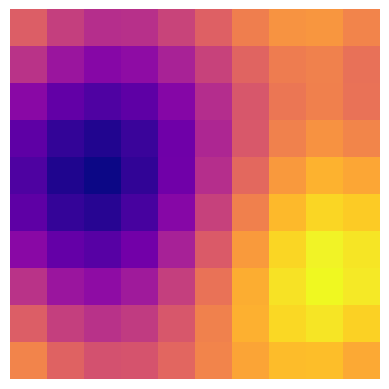

In [4]:
fig, ax = plt.subplots()
ax.imshow(noise, origin='lower', cmap='plasma')
ax.axis('off')

### Perlin 3d

In [6]:
import random
import math

def fade(t):
    """Fade function as defined by Ken Perlin."""
    return t * t * t * (t * (t * 6 - 15) + 10)

def lerp(a, b, t):
    """Linear interpolation function."""
    return a + t * (b - a)

def grad(hash, x, y, z):
    """Convert low 4 bits of hash code into 12 gradient directions."""
    h = hash & 15
    u = x if h < 8 else y  # Gradient direction
    v = y if h < 4 else (x if h == 12 or h == 14 else z)  # Gradient direction
    return (u if (h & 1) == 0 else -u) + (v if (h & 2) == 0 else -v)

def perlin(x, y, z, permutation):
    """Generate Perlin noise at coordinates x, y, z."""
    # Determine grid cell coordinates
    X = int(math.floor(x)) & 255
    Y = int(math.floor(y)) & 255
    Z = int(math.floor(z)) & 255
    # print(X, Y, Z)

    # Relative x, y, z in the grid cell
    x -= math.floor(x)
    y -= math.floor(y)
    z -= math.floor(z)

    # Fade the x, y, z values
    u = fade(x)
    v = fade(y)
    w = fade(z)

    # Hash coordinates of the cube corners
    aaa = permutation[permutation[permutation[X] + Y] + Z]
    aba = permutation[permutation[permutation[X] + Y + 1] + Z]
    aab = permutation[permutation[permutation[X] + Y] + Z + 1]
    abb = permutation[permutation[permutation[X] + Y + 1] + Z + 1]
    baa = permutation[permutation[permutation[X + 1] + Y] + Z]
    bba = permutation[permutation[permutation[X + 1] + Y + 1] + Z]
    bab = permutation[permutation[permutation[X + 1] + Y] + Z + 1]
    bbb = permutation[permutation[permutation[X + 1] + Y + 1] + Z + 1]

    # Blend the results
    x1 = lerp(grad(aaa, x, y, z), grad(aba, x, y - 1, z), v)
    x2 = lerp(grad(baa, x - 1, y, z), grad(bba, x - 1, y - 1, z), v)
    y1 = lerp(x1, x2, u)
    # print(f'x1={x1} x2={x2} -> y1={y1}')

    x1 = lerp(grad(aab, x, y, z - 1), grad(abb, x, y - 1, z - 1), v)
    x2 = lerp(grad(bab, x - 1, y, z - 1), grad(bbb, x - 1, y - 1, z - 1), v)
    y2 = lerp(x1, x2, u)
    # print(f'x3={x1} x3={x2} -> y2={y2}')

    # print(f'val={lerp(y1, y2, w)}')

    return (lerp(y1, y2, w) + 1) / 2  # Normalize to [0,1]

def generate_permutation():
    """Generate a random permutation of numbers from 0 to 255."""
    p = list(range(256))
    random.Random(37).shuffle(p)
    return p * 2  # Duplicate the list to avoid wrapping

def generate_perlin_noise_3d(width, height, depth, scale):
    """Generate a 3D array of Perlin noise."""
    permutation = generate_permutation()
    noise = [[[0 for _ in range(width)] for _ in range(height)] for _ in range(depth)]
    
    for z in range(depth):
        for y in range(height):
            for x in range(width):
                noise[z][y][x] = perlin(x / scale, y / scale, z / scale, permutation)
    
    return noise

# Пример использования:
width, height, depth = 9, 20, 20
scale = 10.0
noise_3d = generate_perlin_noise_3d(width, height, depth, scale)


### Values hist and stats

In [38]:
flat_list = []
for z in range(depth):
    for row in noise_3d[z]:
        flat_list.extend(row)

fig, ax = plt.subplots()
ax.hist(flat_list)

(array([ 61., 148., 244., 456., 625., 780., 659., 401., 160.,  66.]),
 array([0.16242339, 0.22683706, 0.29125072, 0.35566438, 0.42007804,
        0.4844917 , 0.54890536, 0.61331902, 0.67773268, 0.74214634,
        0.80656   ]),
 <BarContainer object of 10 artists>)

In [13]:
print(min(flat_list), sum(flat_list) / len(flat_list), max(flat_list))

0.1624233947200001 0.49908418909066665 0.8065599999999999


In [42]:
plt.ion()  # Включение интерактивного режима
fig, axs = plt.subplots(1, 2)

for z in range(depth):
    for ax in axs:
        ax.clear()
    axs[0].imshow(noise_3d[z],origin='lower', cmap='inferno', vmin=0., vmax=1.)
    axs[1].imshow([[0 if (x_i, y_i) not in mask else noise_3d[z][y_i][x_i] for x_i in range(sizeX)] for y_i in range(sizeY)],
        origin='lower', cmap='inferno', vmin=0., vmax=1.)
    for ax in axs:
        ax.axis('off')  # Убираем оси

    plt.pause(0.1)  # Задержка для обновления изображения

### Real-time viz

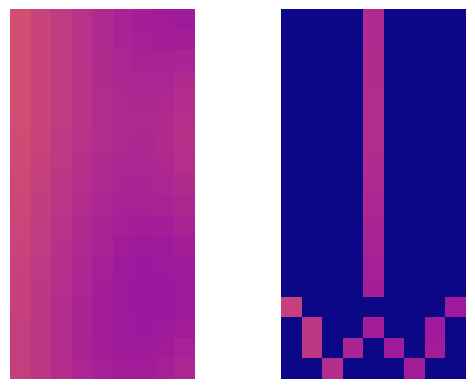

In [12]:
from IPython.display import display, clear_output
plt.ion()  # Включение интерактивного режима
fig, axs = plt.subplots(1, 2)

z = 0
lenScale = 5.0
speedScale = 100.0
width, height = 9, 18
while True:
    try:
        permutation = generate_permutation()
        noise = [[0 for _ in range(width)] for _ in range(height)]

        for y in range(height):
            for x in range(width):
                noise[y][x] = perlin(x / (lenScale * 3.0), y / (lenScale * 3.0), z / speedScale, permutation)
        for ax in axs:
            ax.clear()
        axs[0].imshow(noise,origin='lower', cmap='plasma', vmin=0., vmax=1.)
        axs[1].imshow([[0 if (x_i, y_i) not in mask else noise[y_i][x_i] for x_i in range(sizeX)] for y_i in range(sizeY)],
            origin='lower', cmap='plasma', vmin=0., vmax=1.)
        for ax in axs:
            ax.axis('off')  # Убираем оси

        z += 1
        display(fig)
        clear_output(wait=True)

        plt.pause(1 / 30.0)  # Задержка для обновления изображения
    except KeyboardInterrupt:
        break